# Entropia da fibra do mapa aleatório de Pelikan — notebook de apoio

Este notebook gera **todas as figuras dos slides** (pasta `figs/`).

**O sistema.** A cada passo sorteamos uma moeda e aplicamos ao ponto $x\in[0,1)$:

* $f_0(x) = x/2$ (contrai), com probabilidade $1-p$;
* $f_1(x) = 2x \bmod 1$ (expande), com probabilidade $p$.

**Resultado exato** (nota da Graciela): $h_{\text{fib}}(p) = (2p-1)^+ \log 2$.

**Organização:**
1. Funções básicas
2. Gráficos 1–2: trajetórias e dois pontos
3. Gráficos 3–4: dígitos binários, passeio e recorde
4. Gráfico 5: medida estacionária
5. Gráfico 6: matrizes de Ulam
6. Gráficos 7–8: entropia contra $p$ e convergência
7. Célula para usar ao vivo

In [1]:
# Bibliotecas
import numpy as np                      # contas com vetores
import matplotlib.pyplot as plt         # gráficos
from fractions import Fraction          # frações exatas (sem erro de arredondamento)
from scipy.stats import binom           # probabilidades binomiais
import os

os.makedirs("figs", exist_ok=True)      # pasta onde as figuras são salvas
LOG2 = np.log(2)
AZUL, LARANJA, CINZA, ROXO = "#2563eb", "#ea580c", "#6b7280", "#7c3aed"
plt.rcParams.update({"font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False})

def salvar(nome):
    # Salva a figura atual em figs/<nome>.png e mostra no notebook.
    plt.tight_layout()
    plt.savefig(f"figs/{nome}.png", dpi=150)
    plt.show()

## 1. Funções básicas

* `aplica(s, x)`: aplica $f_0$ (se `s = 0`) ou $f_1$ (se `s = 1`).
* `sorteia(p, n)`: sorteia $n$ moedas com $P(1) = p$.

**Sobre precisão:** em ponto flutuante, $2x \bmod 1$ joga fora um dígito binário por passo e a órbita acaba virando 0.
Por isso, nas trajetórias usamos `Fraction`, que guarda o número **exatamente**.

In [2]:
def aplica(s, x):
    # s = 0 -> contrai (x/2);  s = 1 -> expande (2x mod 1).
    if s == 0:
        return x / 2
    return (2 * x) % 1

def sorteia(p, n, semente=0):
    # Devolve um vetor de n moedas (0 ou 1), com probabilidade p de dar 1.
    rng = np.random.default_rng(semente)
    return (rng.random(n) < p).astype(int)

def h_exato(p):
    # Entropia da fibra exata: (2p - 1)^+ log 2.
    return np.maximum(2 * p - 1, 0) * LOG2

# Ponto inicial "genérico": uma fração com 400 dígitos binários aleatórios.
rng = np.random.default_rng(1)
bits = "".join(rng.choice(["0", "1"], 400))
x0 = Fraction(int(bits, 2), 2**400)
print("x0 ≈", float(x0))

x0 ≈ 0.4497804382210754


## 2. Gráficos 1 e 2 — trajetórias e dois pontos com os mesmos sorteios

**Gráfico 1:** uma órbita para $p = 0{,}3$ e para $p = 0{,}7$.

**Gráfico 2:** dois pontos a $10^{-9}$ de distância recebem **a mesma** sequência de sorteios.
Cada $f_1$ dobra a distância e cada $f_0$ divide por 2, então $|x_n - y_n| \approx 2^{S_n}\,|x_0 - y_0|$.

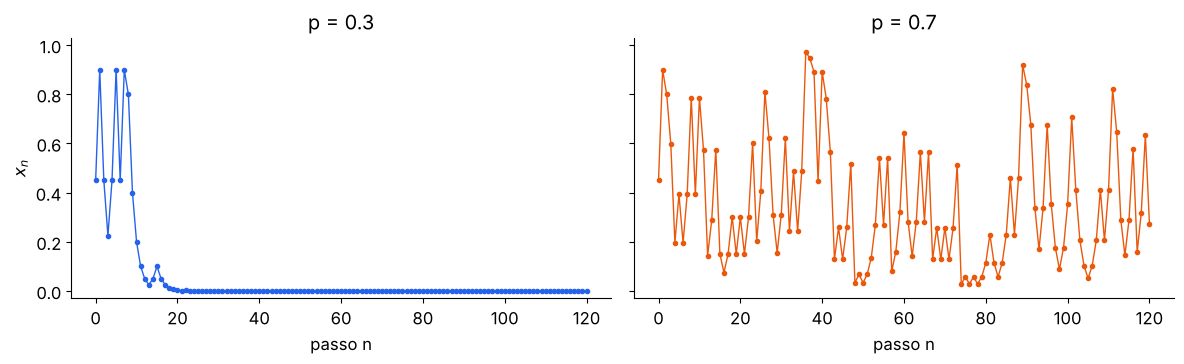

In [3]:
# ---- Gráfico 1: trajetórias
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for eixo, p, cor in zip(eixos, [0.3, 0.7], [AZUL, LARANJA]):
    moedas = sorteia(p, 120, semente=11)
    x = x0
    orbita = [x]
    for s in moedas:                 # aplica os mapas sorteados, um por um
        x = aplica(s, x)
        orbita.append(x)
    eixo.plot([float(v) for v in orbita], "o-", ms=3, lw=1, color=cor)
    eixo.set(title=f"p = {p}", xlabel="passo n", ylim=(-0.03, 1.03))
eixos[0].set_ylabel("$x_n$")
salvar("f1_trajetorias")

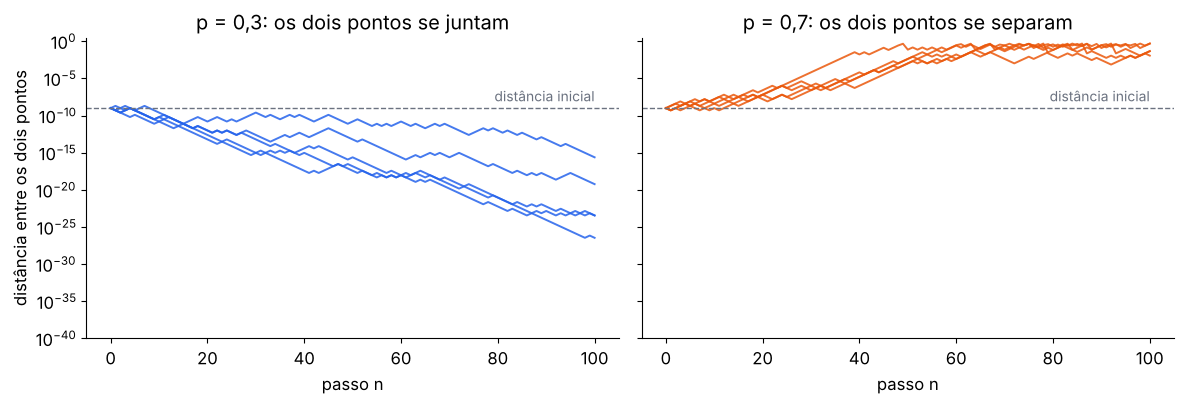

In [4]:
# ---- Gráfico 2: dois pontos quase iguais recebem os MESMOS sorteios
# Painel da esquerda: p = 0,3. Painel da direita: p = 0,7.
# Cada curva é uma sequência de sorteios diferente.
def distancia_circulo(a, b):
    # Distância no círculo [0,1): o menor entre |a-b| e 1-|a-b|.
    d = abs(a - b)
    return min(d, 1 - d)

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
paineis = [(0.3, AZUL, "p = 0,3: os dois pontos se juntam"),
           (0.7, LARANJA, "p = 0,7: os dois pontos se separam")]
for eixo, (p, cor, titulo) in zip(eixos, paineis):
    for semente in range(5):                       # 5 sequências sorteadas
        moedas = sorteia(p, 100, semente=100 + semente)
        x, y = x0, x0 + Fraction(1, 10**9)         # dois pontos a 10^-9
        dist = [1e-9]
        for s in moedas:
            x, y = aplica(s, x), aplica(s, y)      # MESMO mapa nos dois
            dist.append(float(distancia_circulo(x, y)))
        eixo.semilogy(dist, color=cor, lw=1.4, alpha=0.85)
    eixo.axhline(1e-9, color=CINZA, ls="--", lw=1)
    eixo.text(100, 3e-9, "distância inicial", ha="right", va="bottom", color=CINZA, fontsize=10)
    eixo.set(title=titulo, xlabel="passo n", ylim=(1e-40, 3))
eixos[0].set_ylabel("distância entre os dois pontos")
salvar("f2_distancia")

## 3. Gráfico 3 — curiosidade: no computador, a órbita "morre"

Um número `double` guarda **53 dígitos binários**. Em binário, $f_1(x) = 2x \bmod 1$ **apaga o primeiro dígito**
e $f_0(x) = x/2$ só **insere um 0** (não perde nada).

* Com $p = 1$ (só $2x \bmod 1$): depois de 53 passos não sobra dígito nenhum e $x$ vira **exatamente 0** — para sempre.
* Com $p$ qualquer: cada passo consome, em média, $(2p-1)$ dígitos — que é a **entropia em bits por passo**.
  Então a órbita morre em
  $$T \approx \frac{53 \text{ bits}}{(2p-1) \text{ bits por passo}}.$$

**Por que isso importa:** simular órbitas longas em `double` dá resultado errado. Por isso as trajetórias usam
`Fraction`, e o método de Ulam só aplica $n$ passos a cada célula.

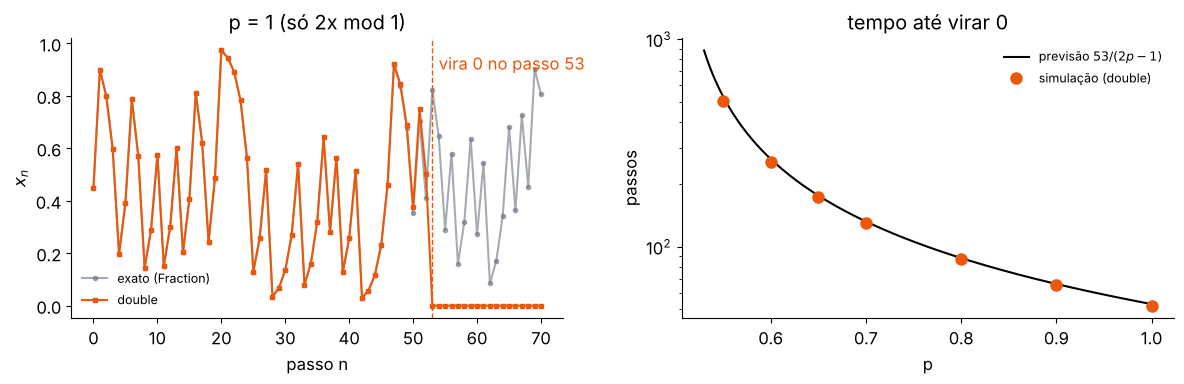

In [5]:
# ---- Gráfico 3: a órbita em double "morre"; o tempo de morte mede a entropia
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))

# (a) p = 1: só 2x mod 1. Mesma condição inicial em double e em fração exata.
x_float = float(x0)
x_exato = x0
orb_float, orb_exata = [x_float], [float(x_exato)]
for n in range(70):
    x_float = (2 * x_float) % 1.0
    x_exato = (2 * x_exato) % 1
    orb_float.append(x_float)
    orb_exata.append(float(x_exato))
morte = next(n for n, v in enumerate(orb_float) if v == 0.0)
eixos[0].plot(orb_exata, "o-", ms=3, color=CINZA, alpha=.6, label="exato (Fraction)")
eixos[0].plot(orb_float, "s-", ms=3, color=LARANJA, label="double")
eixos[0].axvline(morte, color=LARANJA, ls="--", lw=1)
eixos[0].text(morte + 1, 0.9, f"vira 0 no passo {morte}", color=LARANJA)
eixos[0].set(title="p = 1 (só 2x mod 1)", xlabel="passo n", ylabel="$x_n$")
eixos[0].legend(frameon=False, fontsize=9, loc="lower left")

# (b) tempo até o double virar 0, para vários p (média de 300 órbitas)
rng = np.random.default_rng(0)
ps_m = [0.55, 0.6, 0.65, 0.7, 0.8, 0.9, 1.0]
tempos = []
for p in ps_m:
    T = []
    for _ in range(300):
        x, n = rng.random(), 0
        while x != 0.0:                       # roda até a órbita virar exatamente 0
            x = (2 * x) % 1.0 if rng.random() < p else x / 2
            n += 1
        T.append(n)
    tempos.append(np.mean(T))
pp = np.linspace(0.53, 1, 200)
eixos[1].plot(pp, 53 / (2 * pp - 1), color="black", lw=1.5,
              label=r"previsão $53/(2p-1)$")
eixos[1].plot(ps_m, tempos, "o", color=LARANJA, ms=8, label="simulação (double)")
eixos[1].set_yscale("log")
eixos[1].set(title="tempo até virar 0", xlabel="p", ylabel="passos")
eixos[1].legend(frameon=False, fontsize=9)
salvar("f3_float")

### Gráfico 4 — passeio e recorde
O passeio $S_n$ (+1 para $f_1$, −1 para $f_0$) bate um **novo recorde** $M_n$ exatamente quando $f_1$ apaga um
dígito **original** de $x$ (informação nova).

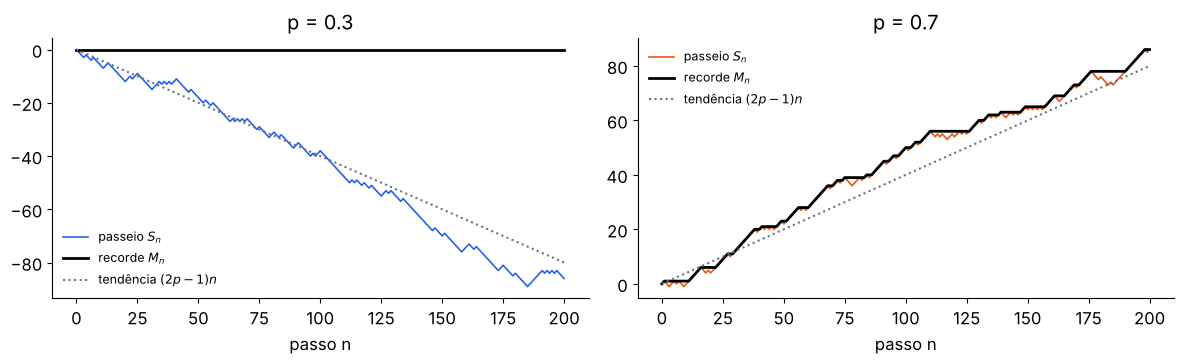

In [6]:
# ---- Gráfico 4: passeio S_n e recorde M_n
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.8))
for eixo, p, cor in zip(eixos, [0.3, 0.7], [AZUL, LARANJA]):
    moedas = sorteia(p, 200, semente=7)
    S = np.concatenate([[0], np.cumsum(2 * moedas - 1)])   # +1 se f1, -1 se f0
    M = np.maximum.accumulate(S)                           # recorde até o momento
    n = np.arange(len(S))
    eixo.plot(S, color=cor, lw=1.2, label="passeio $S_n$")
    eixo.plot(M, color="black", lw=2, label="recorde $M_n$")
    eixo.plot(n, (2 * p - 1) * n, ":", color=CINZA, label="tendência $(2p-1)n$")
    eixo.set(title=f"p = {p}", xlabel="passo n")
    eixo.legend(frameon=False, fontsize=9)
salvar("f4_passeio")

## 4. Gráfico 5 — medida estacionária

Pelos dígitos, depois de $n$ passos: $x_n = 2^{-L}\,U$, onde

* $L = M_n - S_n$ é o número de zeros inseridos que ainda estão na frente;
* $U$ é formado pelos dígitos originais ainda não lidos (uniforme, se $x_0$ é uniforme).

Isso permite amostrar $x_n$ **exatamente**, sem problema de ponto flutuante.
Para $p > 1/2$, a curva preta é uma previsão: $L$ geométrico de razão $r = (1-p)/p$ *(conferir)*.

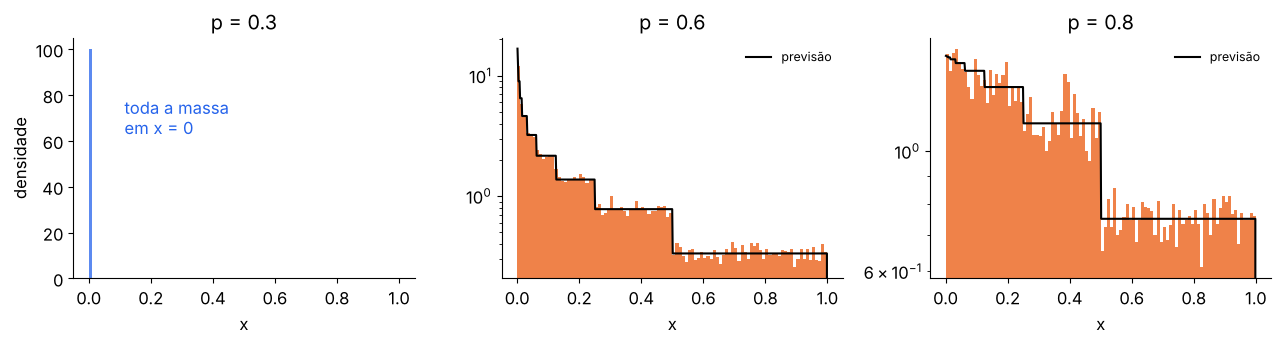

In [7]:
rng = np.random.default_rng(3)
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.6))
for eixo, p in zip(eixos, [0.3, 0.6, 0.8]):
    n, amostras = 1500, 20000
    passos = np.where(rng.random((amostras, n)) < p, 1, -1)   # +1 (f1) ou -1 (f0)
    S = passos.cumsum(axis=1)
    M = np.maximum(S.max(axis=1), 0)
    L = M - S[:, -1]                                          # zeros na frente
    U = rng.random(amostras)
    x = np.where(L < 1000, U * 2.0 ** (-np.minimum(L, 1000)), 0.0)
    eixo.hist(x, bins=100, range=(0, 1), density=True, alpha=.75,
              color=LARANJA if p > .5 else AZUL)
    if p > .5:
        r = (1 - p) / p
        xs = np.linspace(1e-3, 1, 600)
        dens = sum((1 - r) * r**k * 2**k * (xs < 2.0**-k) for k in range(60))
        eixo.plot(xs, dens, "k", lw=1.5, label="previsão")
        eixo.set_yscale("log"); eixo.legend(frameon=False, fontsize=9)
    else:
        eixo.text(.15, .6, "toda a massa\nem x = 0", transform=eixo.transAxes, color=AZUL)
    eixo.set(title=f"p = {p}", xlabel="x")
eixos[0].set_ylabel("densidade")
salvar("f5_medida")

## 5. Gráfico 6 — matrizes de Ulam

Para uma palavra $\omega$ (sequência de mapas) e $2^K$ células:

$$U^{(\omega)}_{ij} = \text{fração da célula } i \text{ que termina na célula } j.$$

Na prática: colocamos muitos pontos igualmente espaçados em cada célula, aplicamos os mapas
e contamos onde cada ponto termina.

(Aqui o ponto flutuante não atrapalha: $n$ é pequeno, e $x/2$ e $2x \bmod 1$ são exatos em binário.)

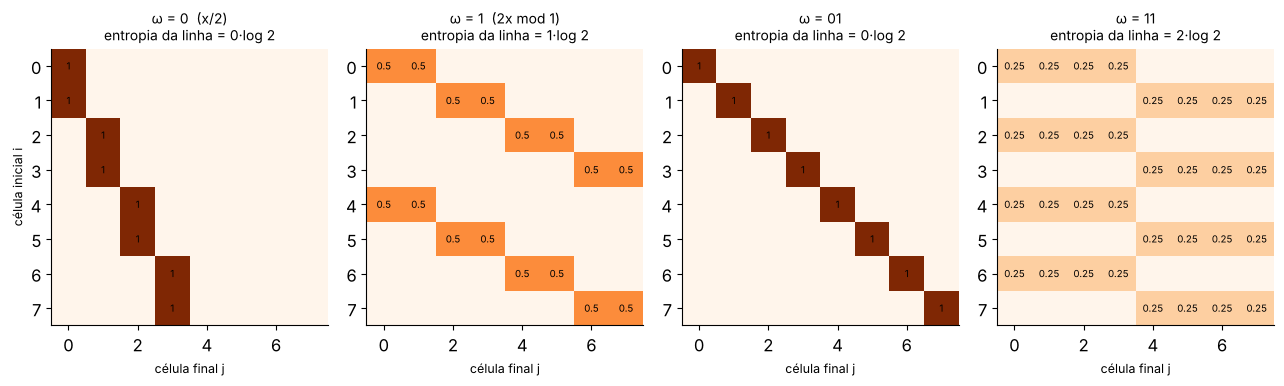

In [8]:
def matriz_ulam(palavra, K, pontos_por_celula=256):
    # Matriz U (2^K x 2^K): fração da célula i que termina na célula j.
    m = 2**K
    U = np.zeros((m, m))
    for i in range(m):
        # pontos igualmente espaçados dentro da célula i = [i/m, (i+1)/m)
        x = (i + (np.arange(pontos_por_celula) + 0.5) / pontos_por_celula) / m
        for s in palavra:                          # aplica a palavra inteira
            x = x / 2 if s == 0 else (2 * x) % 1.0
        j = np.minimum((x * m).astype(int), m - 1) # célula final de cada ponto
        for jj in j:
            U[i, jj] += 1 / pontos_por_celula
    return U

def entropia_linha(linha):
    # Entropia de Shannon de uma linha: -soma q log q (ignorando zeros).
    q = linha[linha > 0]
    return -np.sum(q * np.log(q))

fig, eixos = plt.subplots(1, 4, figsize=(13, 3.6))
for eixo, palavra, nome in zip(eixos, [[0], [1], [0, 1], [1, 1]],
                               ["ω = 0  (x/2)", "ω = 1  (2x mod 1)", "ω = 01", "ω = 11"]):
    U = matriz_ulam(palavra, K=3)
    eixo.imshow(U, cmap="Oranges", vmin=0, vmax=1)
    for i in range(8):
        for j in range(8):
            if U[i, j] > 0:
                eixo.text(j, i, f"{U[i, j]:.2g}", ha="center", va="center", fontsize=7)
    eixo.set_title(f"{nome}\nentropia da linha = {round(entropia_linha(U[0]) / LOG2)}·log 2",
                   fontsize=10)
    eixo.set_xlabel("célula final j", fontsize=9)
eixos[0].set_ylabel("célula inicial i", fontsize=9)
salvar("f6_matrizes")

## 6. Gráficos 7 e 8 — entropia contra $p$ e convergência

**Estimador de Ulam** (eq. 16 da nota):

$$\hat h_n(p) = \frac{1}{n}\sum_{\omega} P_p(\omega)\;\overline{\text{entropia das linhas de } U^{(\omega)}}.$$

Duas formas de calcular:
* `h_ulam_matrizes`: constrói as matrizes de verdade (lento, só para $n$ pequeno);
* `h_formula`: usa a fórmula fechada (eq. 17), em que a entropia da linha é $(S)^+\log 2$:
$$\hat h_n(p) = \frac{\log 2}{n}\sum_{j=0}^n \binom{n}{j} p^j (1-p)^{n-j} (2j-n)^+.$$

In [9]:
def h_ulam_matrizes(p, n):
    # Estimador de Ulam construindo as matrizes (malha K = n).
    total = 0.0
    for w in range(2**n):                                  # todas as palavras de tamanho n
        palavra = [(w >> k) & 1 for k in range(n)]
        prob = p**sum(palavra) * (1 - p)**(n - sum(palavra))
        U = matriz_ulam(palavra, K=n, pontos_por_celula=2**(n + 2))
        media_linhas = np.mean([entropia_linha(linha) for linha in U])
        total += prob * media_linhas                       # entropia primeiro, média depois
    return total / n

def h_formula(p, n):
    # Mesma coisa pela fórmula (17): j = número de expansões ~ Binomial(n, p).
    j = np.arange(n + 1)
    return LOG2 / n * np.sum(binom.pmf(j, n, p) * np.maximum(2 * j - n, 0))

def h_recorde(p, n=400, repeticoes=20000, semente=0):
    # Monte Carlo: dígitos novos revelados = recorde M_n do passeio.
    rng = np.random.default_rng(semente)
    S = np.cumsum(np.where(rng.random((repeticoes, n)) < p, 1, -1), axis=1)
    M = np.maximum(S.max(axis=1), 0)
    return M.mean() / n * LOG2

# Conferência: matrizes de verdade x fórmula
for p in [0.3, 0.7, 0.9]:
    print(f"p = {p}:  matrizes = {h_ulam_matrizes(p, 4):.5f}   fórmula = {h_formula(p, 4):.5f}")

p = 0.3:  matrizes = 0.03182   fórmula = 0.03182
p = 0.7:  matrizes = 0.30907   fórmula = 0.30907
p = 0.9:  matrizes = 0.55583   fórmula = 0.55583


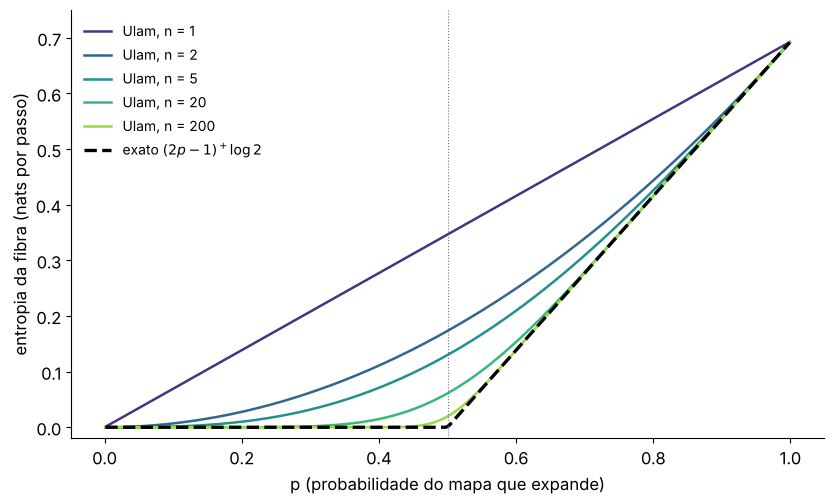

In [10]:
# ---- Gráfico 7: o gráfico principal (só Ulam para vários n e o valor exato)
ps = np.linspace(0.001, 0.999, 200)
plt.figure(figsize=(8.5, 5.2))
cores = plt.cm.viridis(np.linspace(.15, .85, 5))
for cor, n in zip(cores, [1, 2, 5, 20, 200]):
    plt.plot(ps, [h_formula(p, n) for p in ps], color=cor, lw=1.8, label=f"Ulam, n = {n}")
plt.plot(ps, h_exato(ps), "k--", lw=2.4, label="exato $(2p-1)^+\\log 2$")
plt.axvline(.5, color=CINZA, lw=.8, ls=":")
plt.xlabel("p (probabilidade do mapa que expande)")
plt.ylabel("entropia da fibra (nats por passo)")
plt.ylim(-0.02, 0.75); plt.legend(frameon=False, fontsize=10, loc="upper left")
salvar("f7_principal")

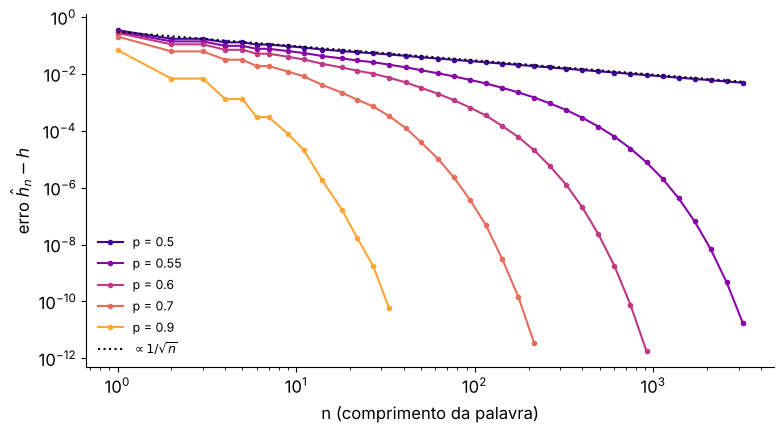

In [11]:
# ---- Gráfico 8: erro do estimador contra n
ns = np.unique(np.logspace(0, 3.5, 40).astype(int))
plt.figure(figsize=(8, 4.5))
for cor, p in zip(plt.cm.plasma(np.linspace(.1, .8, 5)), [0.5, 0.55, 0.6, 0.7, 0.9]):
    erro = np.array([h_formula(p, n) - h_exato(p) for n in ns])
    ok = erro > 1e-12                                  # esconde o ruído numérico
    plt.loglog(ns[ok], erro[ok], "o-", ms=3, color=cor, label=f"p = {p}")
plt.loglog(ns, 0.3 / np.sqrt(ns), "k:", label="$\\propto 1/\\sqrt{n}$")
plt.xlabel("n (comprimento da palavra)"); plt.ylabel("erro $\\hat h_n - h$")
plt.legend(frameon=False, fontsize=9)
salvar("f8_convergencia")

### Gráfico 9 — $\hat h_n(p)$ contra $n$, para vários $p$
Cada curva é o estimador de Ulam para um $p$; a linha tracejada da mesma cor é o valor exato $(2p-1)^+\log 2$.

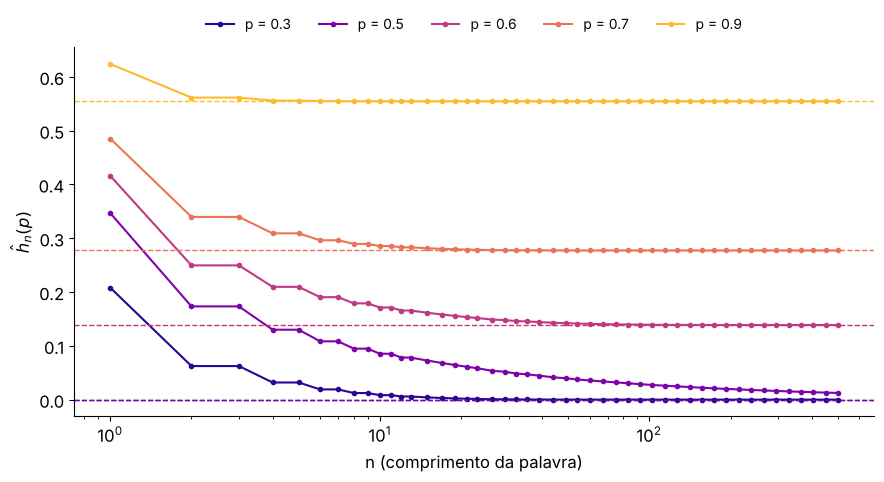

In [12]:
# ---- Gráfico 9: convergência de h_n para vários valores de p
ns = np.unique(np.logspace(0, np.log10(500), 60).astype(int))
plt.figure(figsize=(9, 5))
for cor, p in zip(plt.cm.plasma(np.linspace(.05, .85, 5)), [0.3, 0.5, 0.6, 0.7, 0.9]):
    plt.semilogx(ns, [h_formula(p, n) for n in ns], "o-", ms=3, lw=1.5, color=cor, label=f"p = {p}")
    plt.axhline(h_exato(p), color=cor, ls="--", lw=1)          # valor exato
plt.xlabel("n (comprimento da palavra)")
plt.ylabel(r"$\hat h_n(p)$")
plt.legend(frameon=False, fontsize=10, ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.12))
salvar("f9_convergencia_p")

## 7. Para usar ao vivo

Mude `p` e `n` e rode a célula: mostra $\hat h_n(p)$ (fórmula e matrizes) e o valor exato.
Use `n ≤ 8` com as matrizes (o custo cresce como $4^n$).

In [13]:
p, n = 0.65, 6
print(f"fórmula (17):        {h_formula(p, n):.5f}")
print(f"matrizes de Ulam:    {h_ulam_matrizes(p, n):.5f}")
print(f"Monte Carlo recorde: {h_recorde(p):.5f}")
print(f"exato (2p-1)+ log2:  {h_exato(p):.5f}")

fórmula (17):        0.24066
matrizes de Ulam:    0.24066
Monte Carlo recorde: 0.21014
exato (2p-1)+ log2:  0.20794
